In [3]:
import sys

print("Python Executable:", sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")

Python Executable: c:\dev\churn-prediction\.venv\Scripts\python.exe
All libraries imported successfully!


In [4]:
df= pd.read_csv('data/customer_churn.csv')
print("Dataset Shape", df.shape)

Dataset Shape (7043, 21)


In [5]:
print('Data Info', df.info())


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
print("\n- Missing Values -")
df.isnull().sum()


- Missing Values -


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
print("\n-Churn Class Balance -")
print(df['Churn'].value_counts(normalize=True) * 100)


-Churn Class Balance -
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


C:\Users\Brothers\AppData\Local\Temp\ipykernel_22480\3322687607.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette='pastel', ax=axes[0, 0])
C:\Users\Brothers\AppData\Local\Temp\ipykernel_22480\3322687607.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_churn, x='Contract', y='Churn_Num', palette='coolwarm', ax=axes[0, 1])
C:\Users\Brothers\AppData\Local\Temp\ipykernel_22480\3322687607.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set3', 

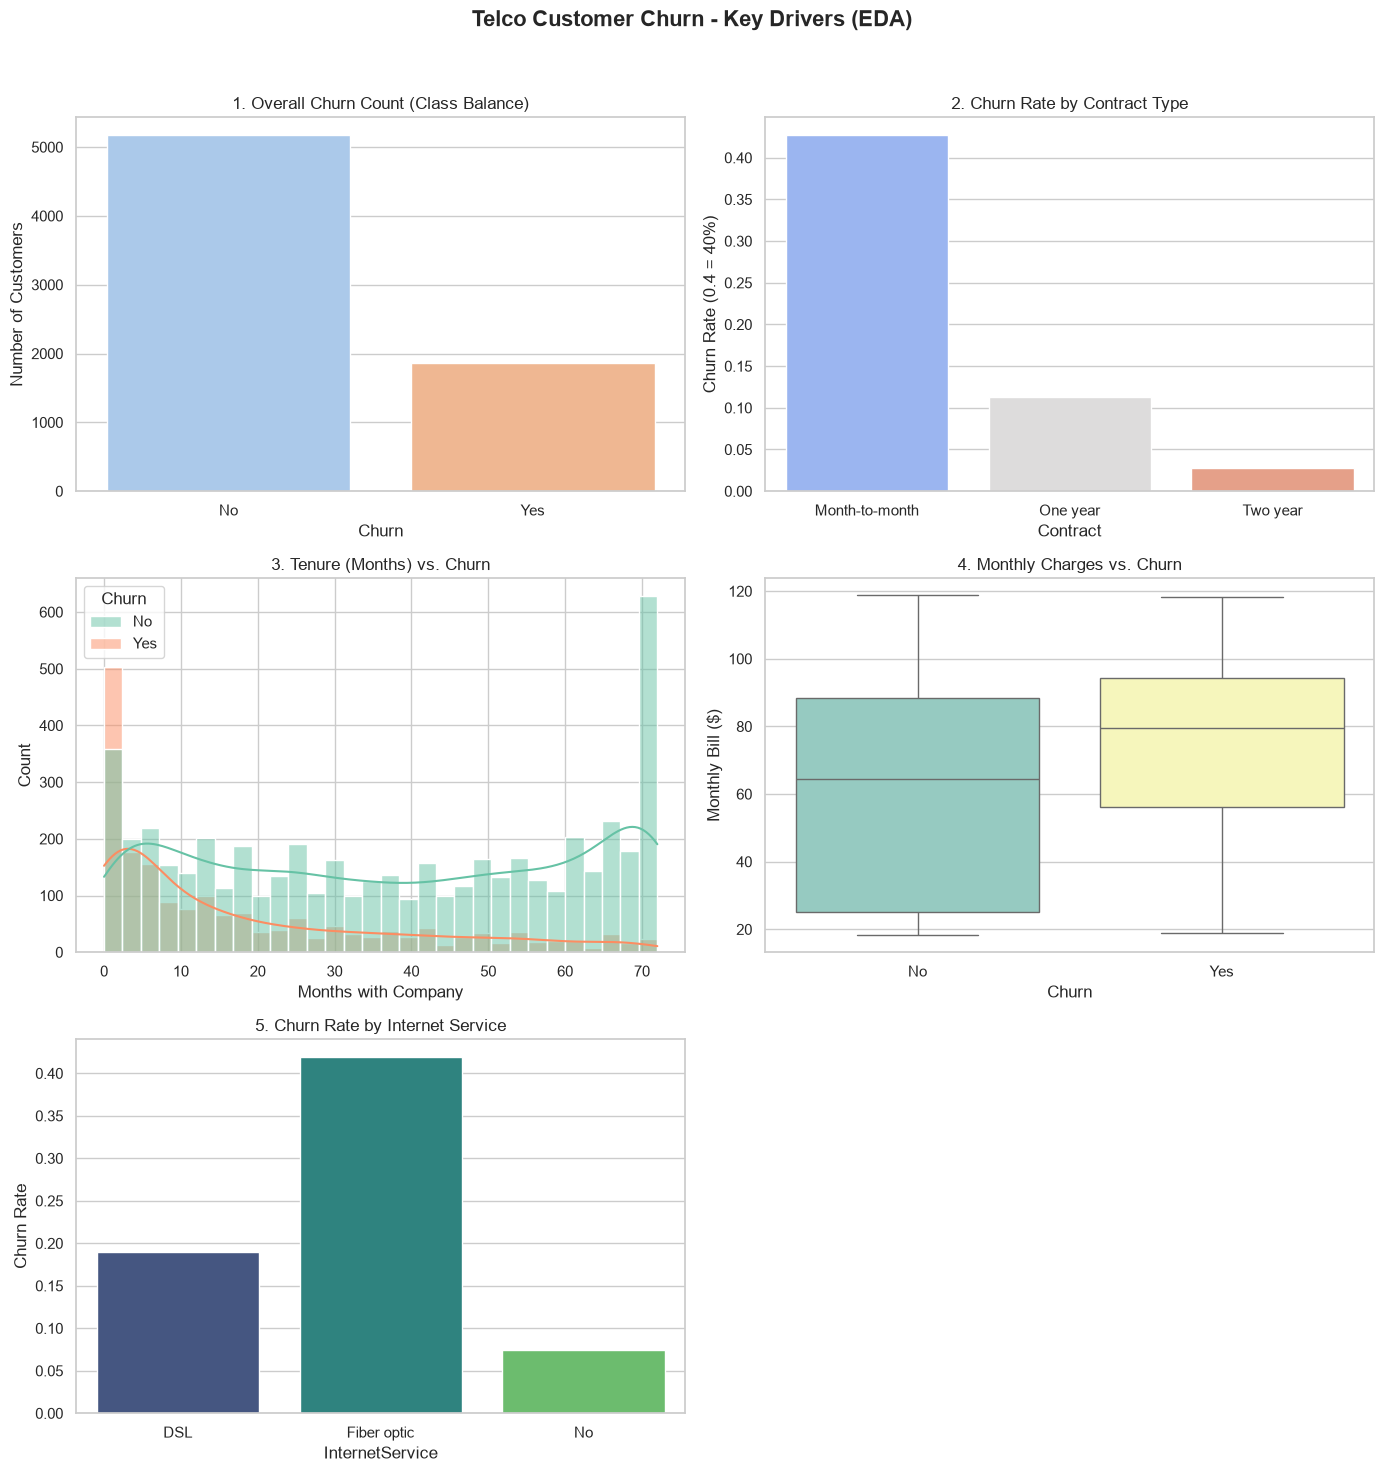

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make sure Churn is numeric (1 = Yes, 0 = No) so we can calculate churn rates easily
df['Churn_Num'] = df['Churn'].map({'Yes': 1, 'No': 0})

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(14, 15))
fig.suptitle('Telco Customer Churn - Key Drivers (EDA)', fontsize=16, fontweight='bold')

# Chart 1: Overall Class Balance (How many stayed vs. left?)
sns.countplot(data=df, x='Churn', palette='pastel', ax=axes[0, 0])
axes[0, 0].set_title('1. Overall Churn Count (Class Balance)')
axes[0, 0].set_ylabel('Number of Customers')

# Chart 2: Churn Rate by Contract Type
contract_churn = df.groupby('Contract')['Churn_Num'].mean().reset_index()
sns.barplot(data=contract_churn, x='Contract', y='Churn_Num', palette='coolwarm', ax=axes[0, 1])
axes[0, 1].set_title('2. Churn Rate by Contract Type')
axes[0, 1].set_ylabel('Churn Rate (0.4 = 40%)')

# Chart 3: Tenure Distribution by Churn (How long do they stay before leaving?)
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30, palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('3. Tenure (Months) vs. Churn')
axes[1, 0].set_xlabel('Months with Company')

# Chart 4: Monthly Charges by Churn (Are expensive plans driving them away?)
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette='Set3', ax=axes[1, 1])
axes[1, 1].set_title('4. Monthly Charges vs. Churn')
axes[1, 1].set_ylabel('Monthly Bill ($)')

# Chart 5: Churn Rate by Internet Service (Bonus high-signal feature!)
internet_churn = df.groupby('InternetService')['Churn_Num'].mean().reset_index()
sns.barplot(data=internet_churn, x='InternetService', y='Churn_Num', palette='viridis', ax=axes[2, 0])
axes[2, 0].set_title('5. Churn Rate by Internet Service')
axes[2, 0].set_ylabel('Churn Rate')

# Hide the empty 6th subplot box
axes[2, 1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Key EDA findings and business insights

* Class Imbalance: Roughly 26.5% of customers in the dataset churned, meaning we must use stratified splitting  and evaluate models with  ROC-AUC / Precision-Recall  rather than raw accuracy alone.
*  Contract Lock-In is the Biggest Driver:  Customers on  Month-to-Month  contracts churn at a massive  ~42.7%  rate, compared to just  11.3%  for One-Year and  2.8%  for Two-Year contracts.
*  Early Tenure Danger Zone:  Churn spikes sharply during the  first 6 months  of a customer's lifecycle; once customers pass the 1-year mark, retention stabilizes significantly.
*  Price & Service Sensitivity:  Churned customers pay noticeably higher median  Monthly Charges (~$80 vs. ~$64) , with  Fiber Optic  users showing the highest churn rate (~41.9%) among internet tiers.
*  Data Cleaning Note:  Fixed 11 blank whitespace strings in `TotalCharges` (all belonging to brand-new customers with `tenure = 0`) by coercing to numeric and imputing `0.0`.

In [10]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

param_dist = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [4, 6, 8, 12, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__class_weight': ['balanced', None] # Helps handle the 26.5% churn imbalance!
}

# Prepare features and target
X = df.drop(columns=['Churn', 'Churn_Num', 'customerID']).copy()
X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')
y = df['Churn'].map({'Yes': 1, 'No': 0})

numeric_features = X.select_dtypes(include='number').columns
categorical_features = X.select_dtypes(exclude='number').columns

preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

best_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42
)

search.fit(X_train, y_train)

tuned_model = search.best_estimator_
print("Best Parameters:", search.best_params_)
print(f"Best CV ROC-AUC: {search.best_score_:.4f}")

Best Parameters: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_depth': 8, 'model__class_weight': 'balanced'}
Best CV ROC-AUC: 0.8483


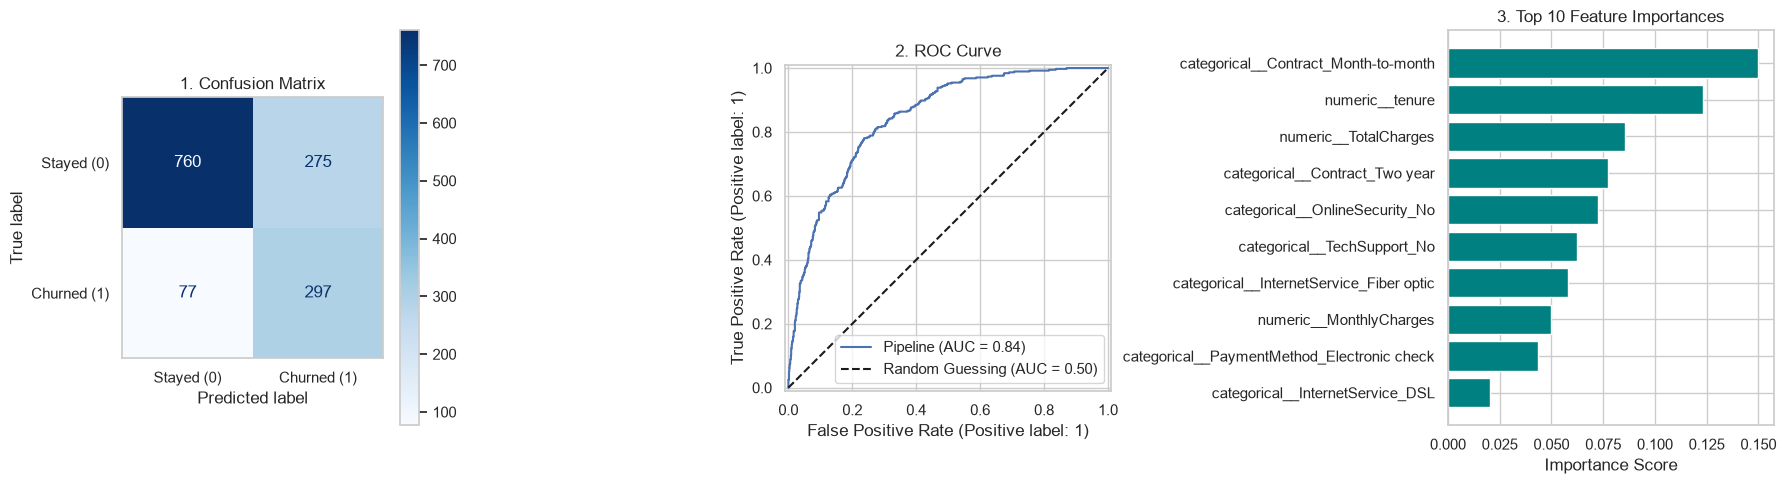

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    tuned_model, X_test, y_test,
    display_labels=['Stayed (0)', 'Churned (1)'],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title('1. Confusion Matrix')
axes[0].grid(False)

# 2. ROC Curve
RocCurveDisplay.from_estimator(tuned_model, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.50)')
axes[1].set_title('2. ROC Curve')
axes[1].legend()

# 3. Top 10 Feature Importances
feature_names = tuned_model.named_steps['preprocessor'].get_feature_names_out()
importances = tuned_model.named_steps['model'].feature_importances_

feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
top_10 = feat_df.sort_values(by='Importance', ascending=False).head(10)

axes[2].barh(top_10['Feature'][::-1], top_10['Importance'][::-1], color='teal')
axes[2].set_title('3. Top 10 Feature Importances')
axes[2].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()